# Этап 4. Подрезание и поперечная RSS

Код: `rssrl/violators.py` (CutInViolator), `rssrl/scenarios.py` (CutInDirector), `rssrl/shield.py` (поперечная RSS, запрет и отмена перестроений). Проверки: `tests/test_cutin.py`.

**Подрезающий**: машина из соседней полосы перестраивается перед агентом за 3 с по гладкой траектории (полином 5-й степени, без телепортации). Маневр начинается, когда прогнозный зазор в момент пересечения разметки равен γ·d_min. Фактический зазор измеряется на разметке. С этого момента подрезающий тормозит с 5 м/с² (β = 1, самое сильное торможение, которое допускает RSS).

**Сцена подрезания**: чтобы было куда подрезать, на старте из полосы агента убраны машины на 250 м вперед. Это одинаково для всех вариантов агента и всех γ.

**Момент подрезания — по расписанию**: момент, машина и полоса берутся из эталонного прогона (IDLE + фильтр ρ), где маневр начинается по прогнозу зазора γ·d_min (d_min — лемма 2 как в статье). У других вариантов агента подрезание начинается в тот же момент, а фактический зазор на разметке зависит от того, как ехал агент, — он записывается (фактическое γ).

**Фильтр**: d_min — лемма 2 с учетом рывка 10 м/с³ (как в ноутбуках 03, 05, 07).

**Фильтр**: ситуация опасна, только если небезопасно и продольно (лемма 2), и поперечно (лемма 4). Подрезающий становится опасным еще до разметки: как только он начинает сдвигаться к агенту, поперечный d_min растет.

In [1]:
import sys
sys.path.insert(0, '..')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rssrl.pilot import run_grid, plot_episode
from rssrl.scenarios import LC_DURATION
from rssrl.responsibility import responsibility_table

FIG = Path('..') / 'results' / 'figures'
PILOT = Path('..') / 'results' / 'pilot_04'  # все графики столкновений, в git не идут
PILOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
SEEDS = range(20)
# основной режим — фильтр с задержкой ρ, дополнительный — мгновенный фильтр
VARIANTS = [(True, 0.5), (True, 0.0), (False, 0.5)]
NAMES = {(True, 0.5): 'фильтр, задержка ρ (основной)', (True, 0.0): 'фильтр, задержка 0 (доп.)',
         (False, 0.5): 'без фильтра'}

In [2]:
outcomes, logs = run_grid(SEEDS, [1.0, 0.25], VARIANTS, kind='cutin', trigger='schedule')
outcomes['вариант'] = [NAMES[(s, d)] for s, d in zip(outcomes['shield'], outcomes['reaction_delay'])]
outcomes.drop(columns=['crash_partners']).to_csv(PILOT / 'outcomes.csv', index=False)
trig = outcomes[outcomes.triggered]
summary = outcomes.groupby(['вариант', 'gamma'], sort=False).agg(
    подрезание_было=('triggered', 'sum'),
    столкновений_всего=('collision', 'sum'),
    с_подрезающим=('hit_violator', 'sum'),
)
summary['доля с подрезающим среди подрезаний'] = (summary['с_подрезающим'] / summary['подрезание_было']).round(2)
summary

,,подрезание_было,столкновений_всего,с_подрезающим,доля с подрезающим среди подрезаний
вариант,gamma,,,,
"фильтр, задержка ρ (основной)",1.00,14,0,0,0.0
"фильтр, задержка 0 (доп.)",1.00,14,0,0,0.0
без фильтра,1.00,14,20,14,1.0
"фильтр, задержка ρ (основной)",0.25,15,0,0,0.0
"фильтр, задержка 0 (доп.)",0.25,14,0,0,0.0
без фильтра,0.25,14,20,14,1.0


Как читать таблицу:
- **Без фильтра** агент врезается во всех эпизодах: он ни на кого не реагирует. Часть столкновений — с другими машинами, еще до подрезания.
- **С фильтром** (d_min с учетом рывка) — 0 столкновений и при законном γ = 1, и при γ = 0,25, при обеих задержках. Для сравнения, с d_min леммы 2 как в статье при задержке ρ было 11 из 12 подрезаний при γ = 1 и 15 из 16 при γ = 0,25 — медленные въезды в остановившегося подрезающего.
- Подрезание случилось в 14–15 сценах из 20: нужна подходящая машина в соседней полосе и место перед агентом. Момент одинаковый для всех вариантов (расписание); в одной сцене у мгновенного фильтра подрезающий к моменту маневра уже был не в соседней полосе, и маневр не состоялся.

## Траектория подрезания: гладкая, без телепортации

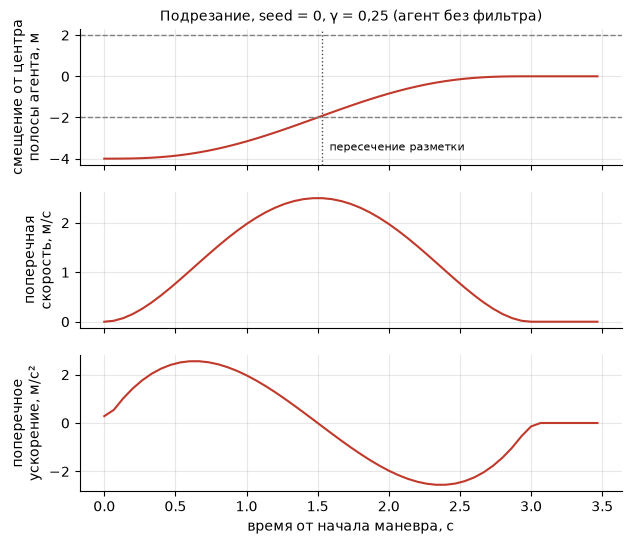

наибольшая поперечная скорость 2.50 м/с, наибольшее поперечное ускорение 2.55 м/с²


In [3]:
o = trig[(~trig.shield) & (trig.gamma == 0.25)].iloc[0]
log = logs[(o.seed, 0.25, False, 0.5)]
t0 = o.t_trigger
# до начала маневра нарушитель еще не назначен — его колонки пустые
part = log[(log.t <= t0 + LC_DURATION + 0.5) & log.vio_y.notna()]
# первая запись — после первого шага маневра; добавляем состояние в момент старта
# (поперечная скорость 0), чтобы производная на краю считалась честно
start = pd.DataFrame({'t': [t0], 'vio_y': [part.vio_y.iloc[0]], 'vio_vy': [0.0]})
part = pd.concat([start, part[['t', 'vio_y', 'vio_vy']]], ignore_index=True)
ay = np.gradient(part['vio_vy'], part['t'])
fig, axes = plt.subplots(3, 1, figsize=(7, 6), sharex=True)
axes[0].plot(part.t - t0, part.vio_y, color='#c0392b')
for y in (-2, 2):
    axes[0].axhline(y, color='0.5', linewidth=1, linestyle='--')
axes[0].axvline(o.t_cross - t0, color='0.3', linewidth=1, linestyle=':')
axes[0].text(o.t_cross - t0 + 0.05, -3.6, 'пересечение разметки', fontsize=8)
axes[0].set_ylabel('смещение от центра\nполосы агента, м')
axes[1].plot(part.t - t0, part.vio_vy, color='#c0392b')
axes[1].set_ylabel('поперечная\nскорость, м/с')
axes[2].plot(part.t - t0, ay, color='#c0392b')
axes[2].set_ylabel('поперечное\nускорение, м/с²')
axes[2].set_xlabel('время от начала маневра, с')
axes[0].set_title(f'Подрезание, seed = {o.seed}, γ = 0,25 (агент без фильтра)', fontsize=10)
for a in axes: a.grid(alpha=0.3)
fig.savefig(FIG / '04_cutin_trajectory.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'наибольшая поперечная скорость {part.vio_vy.abs().max():.2f} м/с, '
      f'наибольшее поперечное ускорение {np.abs(ay).max():.2f} м/с²')

Положение, поперечная скорость и поперечное ускорение непрерывны, маневр длится 3 с. Пиковая поперечная скорость — 1,875·4 м / 3 с = 2,5 м/с, пиковое поперечное ускорение — около 2,6 м/с². Это резкое, но физически возможное перестроение. Ускорение здесь посчитано численно по записанной скорости, поэтому в точках излома (0 и 3 с) видна небольшая погрешность конечной разности; по формуле оно в начале и в конце маневра равно нулю.

## Фактический зазор на разметке

Задано: зазор на разметке = γ·d_min (d_min — лемма 2 как в статье) по прогнозу эталонного прогона при постоянных скоростях. Фактическое γ зависит от того, как ехал агент:
- **с фильтром** γ больше заданного (при γ = 1 в среднем 1,15 у задержки ρ и 1,77 у задержки 0): агент начинает тормозить еще до разметки, когда подрезающий только сдвигается к нему (поперечная RSS), а новая d_min вдобавок держит его дальше;
- **без фильтра** γ меньше заданного (при γ = 1 в среднем 0,91, минимум 0,05): агент без фильтра не тормозит и подъезжает ближе, чем эталон. Поэтому без фильтра при «законном» γ = 1 часть подрезаний фактически оказывается ближе d_min, и за них отвечает и нарушитель (таблица ответственности ниже).

В статье нужно указывать и заданное, и фактическое γ.

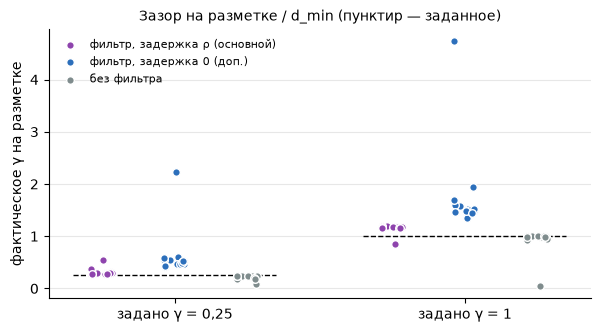

,,mean,min,max
вариант,gamma,,,
"фильтр, задержка ρ (основной)",1.00,1.151,0.848,1.201
"фильтр, задержка 0 (доп.)",1.00,1.768,1.340,4.735
без фильтра,1.00,0.913,0.045,0.998
"фильтр, задержка ρ (основной)",0.25,0.313,0.279,0.547
"фильтр, задержка 0 (доп.)",0.25,0.629,0.417,2.231
без фильтра,0.25,0.220,0.090,0.246


In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
colors = {NAMES[(True, 0.5)]: '#8e44ad', NAMES[(True, 0.0)]: '#2c6fbb', NAMES[(False, 0.5)]: '#7f8c8d'}
for i, g in enumerate([0.25, 1.0]):
    for j, name in enumerate(colors):
        vals = trig[(trig.gamma == g) & (trig['вариант'] == name)]['gamma_actual']
        x = i * 4 + j + np.random.default_rng(0).uniform(-0.15, 0.15, len(vals))
        ax.scatter(x, vals, s=30, color=colors[name], edgecolor='white', linewidth=1,
                   label=name if i == 0 else None, zorder=3)
    ax.hlines(g, i * 4 - 0.4, i * 4 + 2.4, color='black', linewidth=1, linestyle='--')
ax.set_xticks([1, 5]); ax.set_xticklabels(['задано γ = 0,25', 'задано γ = 1'])
ax.set_ylabel('фактическое γ на разметке')
ax.legend(frameon=False, fontsize=8, loc='upper left'); ax.grid(alpha=0.3, axis='y')
ax.set_title('Зазор на разметке / d_min (пунктир — заданное)', fontsize=10)
fig.savefig(FIG / '04_gamma_actual.png', dpi=150, bbox_inches='tight')
plt.show()
trig.groupby(['вариант', 'gamma'], sort=False)['gamma_actual'].agg(['mean', 'min', 'max']).round(3)

## Временные ряды каждого столкновения с фильтром

Четвертая панель — поперечное положение подрезающего относительно центра полосы агента (штрихи — разметка). Графики всех столкновений сохраняются в `results/pilot_04/`, ниже — первые три для каждой задержки (если с фильтром столкновений нет — пример без фильтра).

сохранено графиков: 40
С фильтром столкновений нет. Пример столкновения без фильтра с подрезающим:


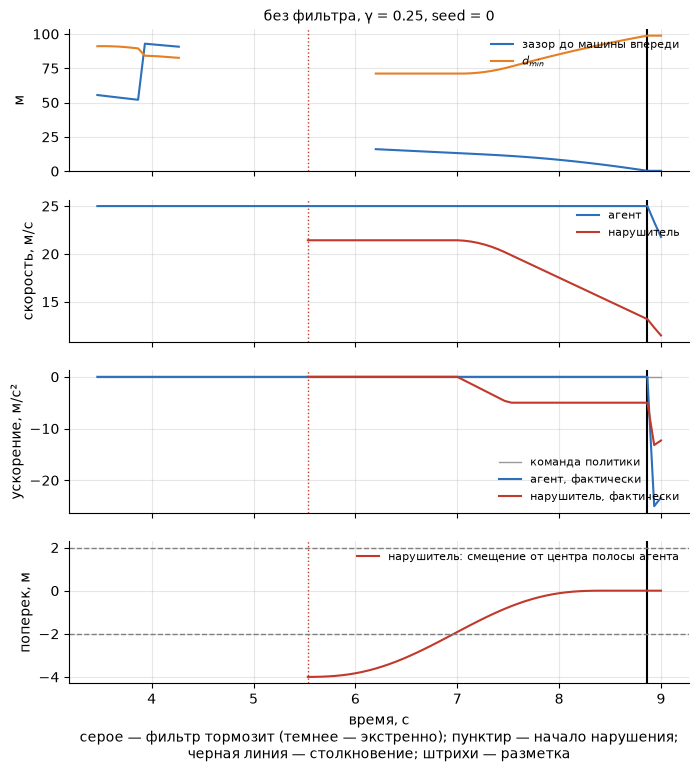

In [5]:
crashes = outcomes[outcomes.collision].sort_values(['shield', 'reaction_delay', 'gamma', 'seed'])
for _, o in crashes.iterrows():
    key = (o.seed, o.gamma, o.shield, o.reaction_delay)
    log = logs[key]
    axes = plot_episode(log, f"{o['вариант']}, γ = {o.gamma:g}, seed = {o.seed}",
                        lateral='vio_y' in log and log['vio_y'].notna().any())
    fig = axes[0].figure
    name = f"{'shield' if o.shield else 'noshield'}_d{o.reaction_delay:g}_g{o.gamma:g}_s{o.seed}.png"
    fig.savefig(PILOT / name, dpi=110, bbox_inches='tight')
    plt.close(fig)
print('сохранено графиков:', len(crashes))

first = True
groups = [crashes[crashes.shield & (crashes.reaction_delay == d)].head(3) for d in [0.5, 0.0]]
if all(g.empty for g in groups):  # с фильтром столкновений нет — пример без фильтра
    print('С фильтром столкновений нет. Пример столкновения без фильтра с подрезающим:')
    groups = [crashes[~crashes.shield & crashes.hit_violator].head(1)]
for sel in groups:
    for _, o in sel.iterrows():
        log = logs[(o.seed, o.gamma, o.shield, o.reaction_delay)]
        part = log[log.t >= o.t_trigger - 2]
        fig, axes = plt.subplots(4, 1, figsize=(8, 8.5), sharex=True)
        plot_episode(part, f"{o['вариант']}, γ = {o.gamma:g}, seed = {o.seed}", axes, lateral=True)
        if first:
            fig.savefig(FIG / '04_collision_example.png', dpi=150, bbox_inches='tight')
            first = False
        plt.show()

## Ответственность за столкновения

Правила те же, что на этапе 3 (`rssrl/responsibility.py`). Для подрезания нарушитель отвечает еще и тогда, когда зазор на разметке меньше d_min (допуск 1 %: при γ = 1 сцена попадает в d_min с точностью до долей процента).

In [6]:
resp = responsibility_table(outcomes, logs)
resp['вариант'] = [NAMES[(s, d)] for s, d in zip(resp['shield'], resp['reaction_delay'])]
resp.to_csv(PILOT / 'responsibility.csv', index=False)
(resp.pivot_table(index=['вариант', 'level'], columns='responsible', values='seed',
                  aggfunc='size', fill_value=0, sort=False)
     .rename_axis(index=['вариант', 'γ'], columns='отвечает'))

отвечает          оба  агент
вариант     γ               
без фильтра 1.00    6     14
            0.25   14      6

In [7]:
# столкновения с фильтром: скорость удара и режим фильтра
outcomes[outcomes.collision & outcomes.shield].groupby(['вариант', 'gamma'], sort=False).agg(
    столкновений=('seed', 'size'),
    скорость_удара_медиана=('v_impact', 'median'),
    скорость_удара_макс=('v_impact', 'max')).round(2)

,,столкновений,скорость_удара_медиана,скорость_удара_макс
вариант,gamma,,,


## Проверка запрета перестроений: агент со случайными действиями

Пилотный агент (IDLE) никогда не перестраивается, поэтому запрет и отмену перестроений он не проверяет. Здесь агент каждую секунду выбирает случайное действие (влево, ничего, вправо, быстрее, медленнее). У случайной политики свой генератор (seed сцены + 1000), он не связан со сценой. Сцена тормозящего лидера, β = 1, допущение соблюдается. С фильтром столкновений быть не должно.

In [8]:
rand, rand_logs = run_grid(SEEDS, [1.0], VARIANTS, kind='brake', policy='random', trigger='schedule')
rand['вариант'] = [NAMES[(s, d)] for s, d in zip(rand['shield'], rand['reaction_delay'])]
rand.groupby('вариант', sort=False).agg(
    столкновений=('collision', 'sum'),
    запросов_перестроения=('lc_requested', 'sum'),
    запрещено=('lc_blocked', 'sum'),
    отменено_начатых=('lc_cancelled', 'sum'),
)

,столкновений,запросов_перестроения,запрещено,отменено_начатых
вариант,,,,
"фильтр, задержка ρ (основной)",0,268,130,3
"фильтр, задержка 0 (доп.)",0,260,123,5
без фильтра,17,85,60,0


In [9]:
# столкновения случайного агента с фильтром: скорость удара и ответственность
rr = responsibility_table(rand, rand_logs)
rr = rr[rr.shield].merge(rand[['seed', 'shield', 'reaction_delay', 'v_impact', 'hit_violator']],
                         on=['seed', 'shield', 'reaction_delay'])
rr[['seed', 'reaction_delay', 'v_impact', 'hit_violator', 'responsible', 'partner_position',
    'reaction_time', 'agent_late', 'agent_released']].round(2)

,seed,reaction_delay,v_impact,hit_violator,responsible,partner_position,reaction_time,agent_late,agent_released


Без фильтра случайный агент разбивается почти всегда (17 из 20). С фильтром столкновений нет при обеих задержках: опасные перестроения запрещаются, начатые — отменяются (только если возвращаться безопасно). Без фильтра в колонках «запрещено» и «отменено» стоит то, что фильтр *запретил бы*.

## Вывод этапа 4

1. Подрезание реализовано гладко: поперечная скорость до 2,5 м/с, поперечное ускорение до ≈ 2,6 м/с², без телепортации.
2. С d_min, учитывающей рывок, у фильтра 0 столкновений при γ = 1 и γ = 0,25 при обеих задержках; у случайной политики в сцене тормозящего лидера — тоже 0.
3. Подрезание — по расписанию, поэтому фактическое γ у вариантов агента разное: с фильтром больше заданного, без фильтра меньше. Его нужно указывать в статье рядом с заданным.
4. Отмена перестроения после исправления: только пока агент не пересек разметку и только если исходная полоса безопасна.